<a href="https://colab.research.google.com/github/nikhilfendre/CSL701-CS15-Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Nikhil Prasad Fendre

Batch :CS1


Roll Number :15



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:

# Task 1: Import Libraries and Load Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
df = pd.read_csv('palmerpenguins_extended.csv')

# Display first five rows
print("First Five Rows:")
print(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


First Five Rows:
  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3430 entries, 0 to 3429
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
-

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:

# Task 2: Select Features and Target & Preprocess

# Handle missing values
df = df.dropna()

# Select input features
X = df[['bill_length_mm',
        'bill_depth_mm',
        'flipper_length_mm',
        'body_mass_g']]

# Select target variable
y = df['species']

# Encode target labels
le = LabelEncoder()
y = le.fit_transform(y)

# Display features and target
print("First Five Rows of Features:")
print(X.head())

print("\nTarget Labels:")
print(le.classes_)

print("\nEncoded Target Values:")
print(y[:5])

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


First Five Rows of Features:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            53.4           17.8              219.0       5687.0
1            49.3           18.1              245.0       6811.0
2            55.7           16.6              226.0       5388.0
3            38.0           15.6              221.0       6262.0
4            60.7           17.9              177.0       4811.0

Target Labels:
['Adelie' 'Chinstrap' 'Gentoo']

Encoded Target Values:
[0 0 0 0 0]

Features Shape: (3430, 4)
Target Shape: (3430,)


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [3]:

# Task 3: Split the Data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Features Shape: (2744, 4)
Testing Features Shape: (686, 4)
Training Target Shape: (2744,)
Testing Target Shape: (686,)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [4]:

# Task 4: Implement CART Classifier

# Create CART classifier
cart_model = DecisionTreeClassifier(criterion='gini', random_state=42)

# Train the model
cart_model.fit(X_train, y_train)

# Predict the test data
y_pred = cart_model.predict(X_test)

print("CART Classifier implemented successfully!")
print("First 10 Actual Labels:", y_test[:10])
print("First 10 Predicted Labels:", y_pred[:10])


CART Classifier implemented successfully!
First 10 Actual Labels: [1 0 2 0 1 0 0 2 1 2]
First 10 Predicted Labels: [0 2 0 0 2 2 2 2 0 2]


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [5]:

# Task 5: Evaluate CART Model

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))


Accuracy: 0.4518950437317784

Confusion Matrix:
[[164  67  73]
 [ 61  27  37]
 [ 89  49 119]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.52      0.54      0.53       304
   Chinstrap       0.19      0.22      0.20       125
      Gentoo       0.52      0.46      0.49       257

    accuracy                           0.45       686
   macro avg       0.41      0.41      0.41       686
weighted avg       0.46      0.45      0.46       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


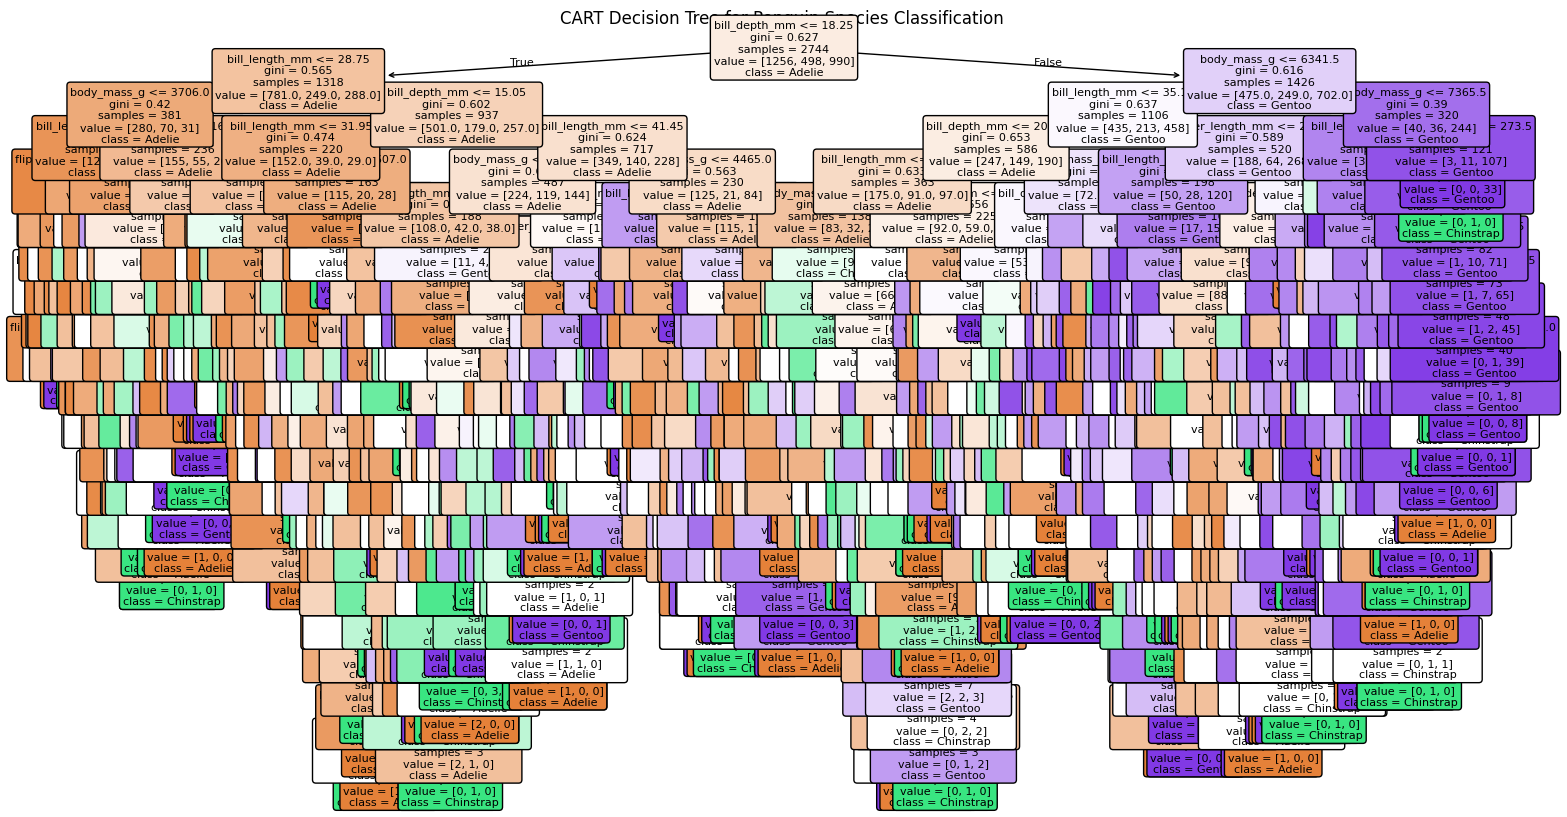

In [6]:

# Task 6: Visualize Decision Tree

plt.figure(figsize=(18, 10))

plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree for Penguin Species Classification")
plt.show()


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


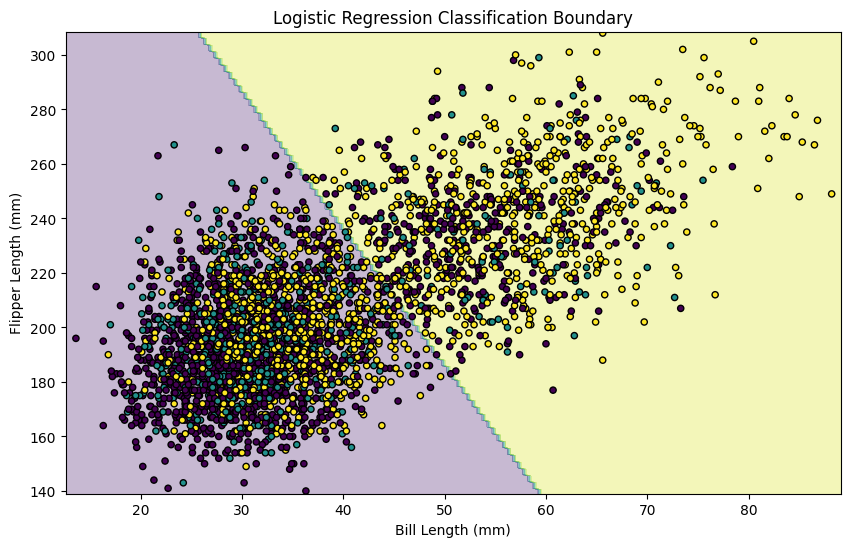

In [8]:

# Task 7: Normal Linear Classification Boundary

# Select two features
X_2d = X[['bill_length_mm', 'flipper_length_mm']]

# Split the data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.2, random_state=42
)

# Create and train Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_2d, y_train_2d)

# Predict the test data
y_pred_lr = lr_model.predict(X_test_2d)

# Create a mesh grid
x_min, x_max = X_2d.iloc[:, 0].min() - 1, X_2d.iloc[:, 0].max() + 1
y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 0.5)
)

# Predict classes for the grid
Z = lr_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the linear classification boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y,
    cmap='viridis',
    edgecolor='black',
    s=20
)

plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('Logistic Regression Classification Boundary')
plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


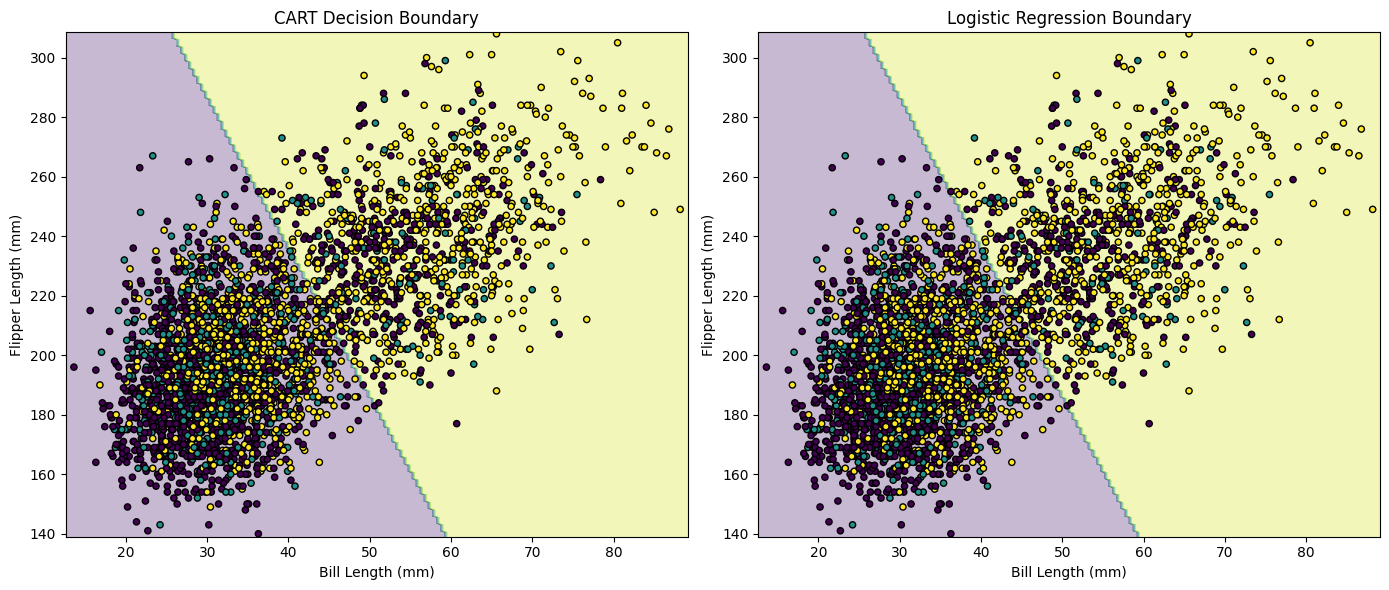

In [9]:

# Task 8: Compare CART and Normal Linear Boundary

plt.figure(figsize=(14, 6))

# CART Decision Boundary
plt.subplot(1, 2, 1)
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y,
    cmap='viridis',
    edgecolor='black',
    s=20
)
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('CART Decision Boundary')

# Logistic Regression Boundary
Z_lr = lr_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z_lr = Z_lr.reshape(xx.shape)

plt.subplot(1, 2, 2)
plt.contourf(xx, yy, Z_lr, alpha=0.3, cmap='viridis')
plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y,
    cmap='viridis',
    edgecolor='black',
    s=20
)
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('Logistic Regression Boundary')

plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

CART Classifier Accuracy: 0.4518950437317784
Logistic Regression Accuracy: 0.5072886297376094


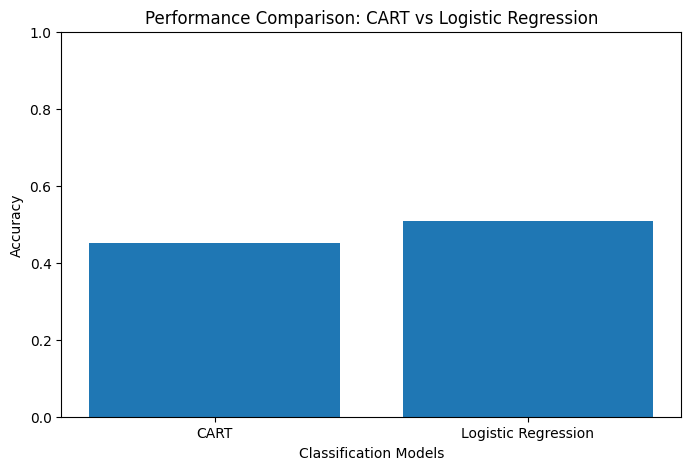

In [10]:

# Task 9: Compare Performance CART vs Logistic Regression

# Calculate accuracy of both models
cart_accuracy = accuracy_score(y_test, y_pred)
lr_accuracy = accuracy_score(y_test_2d, y_pred_lr)

print("CART Classifier Accuracy:", cart_accuracy)
print("Logistic Regression Accuracy:", lr_accuracy)

# Compare model performance
models = ['CART', 'Logistic Regression']
accuracies = [cart_accuracy, lr_accuracy]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.xlabel('Classification Models')
plt.ylabel('Accuracy')
plt.title('Performance Comparison: CART vs Logistic Regression')
plt.ylim(0, 1)
plt.show()


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.